In [1]:
import os, datetime as _dt

def iniciar_ejecucion(nombre, config=None, base="resultados"):
    os.makedirs(base, exist_ok=True)
    nums = []
    for d in os.listdir(base):
        if d.startswith("ejecucion_") and os.path.isdir(os.path.join(base, d)):
            try: nums.append(int(d.split("_")[1]))
            except: pass
    n = max(nums)+1 if nums else 1
    carpeta = os.path.join(base, f"ejecucion_{n}")
    os.makedirs(carpeta)
    with open(os.path.join(carpeta, "config.txt"), "w", encoding="utf-8") as f:
        f.write("notebook : " + str(nombre) + "\n")
        f.write("fecha    : " + _dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S") + "\n")
        if config:
            for k, v in config.items():
                f.write(str(k) + " : " + str(v) + "\n")
    print("[Ejecucion " + str(n) + "] Resultados en: " + carpeta)
    return carpeta

def log(texto, carpeta):
    print(texto)
    with open(os.path.join(carpeta, "resultados.txt"), "a", encoding="utf-8") as f:
        f.write(str(texto) + "\n")

def guardar_csv(resultados, ruta):
    if not resultados: return
    cols = list(resultados[0].keys())
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(",".join(cols) + "\n")
        for r in resultados:
            f.write(",".join(str(r[c]) for c in cols) + "\n")


In [2]:
import numpy as np, os, time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import recall_score, f1_score, roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

DATOS="datos_procesados/ulb.npz"
K=5
METRICA="euclidean"
DIMS=[5,10,15,20,30]
ALGS=["brute","kd_tree","ball_tree"]
N_REP=5

carpeta=iniciar_ejecucion("02b_knn_bb",{"datos":DATOS,"k":K,"metrica":METRICA,"dims":DIMS,"algs":ALGS,"n_rep":N_REP})
d=np.load(DATOS,allow_pickle=True)
Xtr,ytr,Xte,yte=d["X_train"],d["y_train"],d["X_test"],d["y_test"]
N_CONSULTAS=len(Xte)
log(f"Consultas (conjunto de prueba completo): {N_CONSULTAS}",carpeta)
log(f"Cada tiempo medio por consulta = (tiempo total de inferencia sobre las {N_CONSULTAS} consultas) / {N_CONSULTAS},",carpeta)
log(f"promediado sobre {N_REP} repeticiones temporales (se reporta media +/- desviacion).",carpeta)

[Ejecucion 13] Resultados en: resultados\ejecucion_13
Consultas (conjunto de prueba completo): 56746
Cada tiempo medio por consulta = (tiempo total de inferencia sobre las 56746 consultas) / 56746,
promediado sobre 5 repeticiones temporales (se reporta media +/- desviacion).


In [3]:
def medir(alg, nd):
    """Mide el tiempo medio por consulta para un algoritmo y una dimensionalidad,
    repitiendo la inferencia N_REP veces. Devuelve media y desviacion en ms/consulta,
    ademas de las metricas de deteccion (identicas entre algoritmos: poda exacta)."""
    a = Xtr[:, :nd]
    b = Xte[:, :nd]
    modelo = KNeighborsClassifier(n_neighbors=K, metric=METRICA, algorithm=alg, n_jobs=-1)
    modelo.fit(a, ytr)
    _ = modelo.predict_proba(b[:100])
    tiempos_ms = []
    for _ in range(N_REP):
        t0 = time.perf_counter()
        prob = modelo.predict_proba(b)[:, 1]
        dt = time.perf_counter() - t0
        tiempos_ms.append(1000.0 * dt / N_CONSULTAS)
    pred = (prob >= 0.5).astype(int)
    return {
        "dims": nd, "algoritmo": alg,
        "ms_consulta_media": round(float(np.mean(tiempos_ms)), 4),
        "ms_consulta_desv":  round(float(np.std(tiempos_ms)), 4),
        "recall": round(recall_score(yte, pred, zero_division=0), 4),
        "f1":     round(f1_score(yte, pred, zero_division=0), 4),
        "auc_roc":round(roc_auc_score(yte, prob), 4),
        "auc_pr": round(average_precision_score(yte, prob), 4),
    }

filas=[]
for nd in DIMS:
    for alg in ALGS:
        r=medir(alg,nd)
        filas.append(r)
        log(f"d={nd:2d} {alg:10s}: {r['ms_consulta_media']:.4f} +/- {r['ms_consulta_desv']:.4f} ms/consulta",carpeta)
guardar_csv(filas, os.path.join(carpeta,"benchmark_ball_kd_brute.csv"))

d= 5 brute     : 0.0778 +/- 0.0114 ms/consulta
d= 5 kd_tree   : 0.0044 +/- 0.0000 ms/consulta
d= 5 ball_tree : 0.1662 +/- 0.0008 ms/consulta
d=10 brute     : 0.0661 +/- 0.0009 ms/consulta
d=10 kd_tree   : 0.0211 +/- 0.0003 ms/consulta
d=10 ball_tree : 0.5183 +/- 0.0129 ms/consulta
d=15 brute     : 0.1074 +/- 0.0038 ms/consulta
d=15 kd_tree   : 0.0706 +/- 0.0007 ms/consulta
d=15 ball_tree : 0.8882 +/- 0.0108 ms/consulta
d=20 brute     : 0.0822 +/- 0.0039 ms/consulta
d=20 kd_tree   : 0.1515 +/- 0.0014 ms/consulta
d=20 ball_tree : 1.5381 +/- 0.0059 ms/consulta
d=30 brute     : 0.0867 +/- 0.0034 ms/consulta
d=30 kd_tree   : 0.5989 +/- 0.0015 ms/consulta
d=30 ball_tree : 2.1723 +/- 0.0154 ms/consulta


In [4]:
log("\n=== Tiempo medio por consulta (ms), media +/- desv sobre "+str(N_REP)+" repeticiones ===",carpeta)
enc = f"{'d':>4} | {'brute':>18} | {'kd_tree':>18} | {'ball_tree':>18}"
log(enc, carpeta); log("-"*len(enc), carpeta)
for nd in DIMS:
    celdas=[]
    for alg in ALGS:
        r=[x for x in filas if x["dims"]==nd and x["algoritmo"]==alg][0]
        celdas.append(f"{r['ms_consulta_media']:.4f}+/-{r['ms_consulta_desv']:.4f}")
    log(f"{nd:>4} | {celdas[0]:>18} | {celdas[1]:>18} | {celdas[2]:>18}", carpeta)

import csv
ruta=os.path.join(carpeta,"tabla_tiempos_ancho.csv")
with open(ruta,"w",encoding="utf-8") as f:
    f.write("dims,brute_ms,kd_tree_ms,ball_tree_ms,brute_desv,kd_tree_desv,ball_tree_desv\n")
    for nd in DIMS:
        g={a:[x for x in filas if x["dims"]==nd and x["algoritmo"]==a][0] for a in ALGS}
        f.write(f"{nd},{g['brute']['ms_consulta_media']},{g['kd_tree']['ms_consulta_media']},{g['ball_tree']['ms_consulta_media']},"
                f"{g['brute']['ms_consulta_desv']},{g['kd_tree']['ms_consulta_desv']},{g['ball_tree']['ms_consulta_desv']}\n")
log(f"\nTabla guardada en: {ruta}",carpeta)


=== Tiempo medio por consulta (ms), media +/- desv sobre 5 repeticiones ===
   d |              brute |            kd_tree |          ball_tree
-------------------------------------------------------------------
   5 |    0.0778+/-0.0114 |    0.0044+/-0.0000 |    0.1662+/-0.0008
  10 |    0.0661+/-0.0009 |    0.0211+/-0.0003 |    0.5183+/-0.0129
  15 |    0.1074+/-0.0038 |    0.0706+/-0.0007 |    0.8882+/-0.0108
  20 |    0.0822+/-0.0039 |    0.1515+/-0.0014 |    1.5381+/-0.0059
  30 |    0.0867+/-0.0034 |    0.5989+/-0.0015 |    2.1723+/-0.0154

Tabla guardada en: resultados\ejecucion_13\tabla_tiempos_ancho.csv


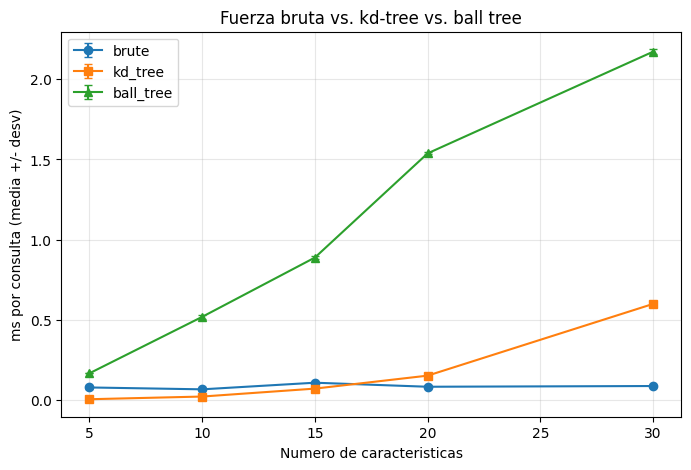


Figura guardada. Metricas de deteccion identicas entre algoritmos (poda exacta): recall=0.5158, f1=0.6622, auc_roc=0.8522


In [5]:
plt.figure(figsize=(8,5))
estilos={"brute":"o-","kd_tree":"s-","ball_tree":"^-"}
for alg in ALGS:
    pares=sorted((x["dims"],x["ms_consulta_media"]) for x in filas if x["algoritmo"]==alg)
    xs=[p[0] for p in pares]; ys=[p[1] for p in pares]
    errs=[[x2["ms_consulta_desv"] for nd in [p[0]] for x2 in filas if x2["dims"]==p[0] and x2["algoritmo"]==alg][0] for p in pares]
    plt.errorbar(xs,ys,yerr=errs,fmt=estilos[alg],capsize=3,label=alg)
plt.xlabel("Numero de caracteristicas"); plt.ylabel("ms por consulta (media +/- desv)")
plt.title("Fuerza bruta vs. kd-tree vs. ball tree"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(os.path.join(carpeta,"cruce_tres_estructuras.png"),dpi=150,bbox_inches="tight"); plt.show()
log(f"\nFigura guardada. Metricas de deteccion identicas entre algoritmos (poda exacta): "
    f"recall={filas[0]['recall']}, f1={filas[0]['f1']}, auc_roc={filas[0]['auc_roc']}",carpeta)